<a href="https://colab.research.google.com/github/veekshavkamath-blip/YEAST/blob/main/YEAST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [228]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [229]:
data=pd.read_csv('yeast.csv')


In [230]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1484 entries, 0 to 1483
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   mcg     1484 non-null   float64
 1   gvh     1484 non-null   float64
 2   alm     1484 non-null   float64
 3   mit     1484 non-null   float64
 4   erl     1484 non-null   float64
 5   pox     1484 non-null   float64
 6   vac     1484 non-null   float64
 7   nuc     1484 non-null   float64
 8   name    1484 non-null   object 
dtypes: float64(8), object(1)
memory usage: 104.5+ KB


In [231]:
data.shape

(1484, 9)

In [232]:
data.head()

,mcg,gvh,alm,mit,erl,pox,vac,nuc,name
0,0.58,0.61,0.47,0.13,0.5,0.0,0.48,0.22,MIT
1,0.43,0.67,0.48,0.27,0.5,0.0,0.53,0.22,MIT
2,0.64,0.62,0.49,0.15,0.5,0.0,0.53,0.22,MIT
3,0.58,0.44,0.57,0.13,0.5,0.0,0.54,0.22,NUC
4,0.42,0.44,0.48,0.54,0.5,0.0,0.48,0.22,MIT


In [233]:
print(data.isnull().sum())
print(data.duplicated().sum())

mcg     0
gvh     0
alm     0
mit     0
erl     0
pox     0
vac     0
nuc     0
name    0
dtype: int64
31


In [234]:
data["name"].value_counts()

,count
name,
CYT,463
NUC,429
MIT,244
ME3,163
ME2,51
ME1,44
EXC,35
VAC,30
POX,20


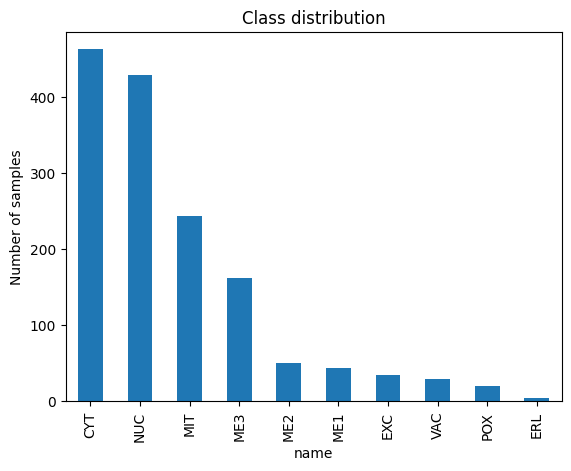

In [235]:
data["name"].value_counts().plot(kind="bar")
plt.title("Class distribution")
plt.ylabel("Number of samples")
plt.show()

In [236]:
dups = data[data.duplicated(keep=False)]   # keep=False shows every copy
print(len(dups))
dups["name"].value_counts()

62


,count
name,
CYT,50
NUC,8
ME1,2
ME3,2


In [237]:
feature_cols = list(data.columns.drop("name"))
label_counts = data.groupby(feature_cols)["name"].nunique()
print((label_counts > 1).sum())

0


In [238]:
clean = data.drop_duplicates().reset_index(drop=True)
print(len(data), "->", len(clean))
print(clean["name"].value_counts())

1484 -> 1453
name
CYT    438
NUC    425
MIT    244
ME3    162
ME2     51
ME1     43
EXC     35
VAC     30
POX     20
ERL      5
Name: count, dtype: int64


In [239]:
y=clean["name"].values
x=clean.drop(columns=["name"]).values

In [240]:
clean["name"].value_counts()

,count
name,
CYT,438
NUC,425
MIT,244
ME3,162
ME2,51
ME1,43
EXC,35
VAC,30
POX,20


In [241]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=42
)
print(x_train.shape, x_test.shape)

(1162, 8) (291, 8)


In [242]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=42)
tree.fit(x_train, y_train)
print("Train accuracy:", tree.score(x_train, y_train))
print("Test accuracy:", tree.score(x_test, y_test))

Train accuracy: 1.0
Test accuracy: 0.5876288659793815


In [243]:
from sklearn.model_selection import StratifiedKFold,cross_val_predict
from sklearn.tree import DecisionTreeClassifier

skf = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)
model = DecisionTreeClassifier(random_state=42)

y_pred = cross_val_predict(model, x_train, y_train, cv=skf)

In [244]:
from sklearn.metrics import classification_report, f1_score, matthews_corrcoef

print(classification_report(y_train, y_pred))
print("Macro F1:", f1_score(y_train, y_pred, average="macro"))
print("MCC:", matthews_corrcoef(y_train, y_pred))

              precision    recall  f1-score   support

         CYT       0.44      0.41      0.42       350
         ERL       0.50      0.25      0.33         4
         EXC       0.58      0.54      0.56        28
         ME1       0.62      0.59      0.61        34
         ME2       0.27      0.24      0.26        41
         ME3       0.64      0.68      0.66       130
         MIT       0.46      0.52      0.49       195
         NUC       0.46      0.46      0.46       340
         POX       0.26      0.31      0.29        16
         VAC       0.11      0.08      0.09        24

    accuracy                           0.47      1162
   macro avg       0.43      0.41      0.42      1162
weighted avg       0.46      0.47      0.46      1162

Macro F1: 0.41556523760705844
MCC: 0.31618638348480166


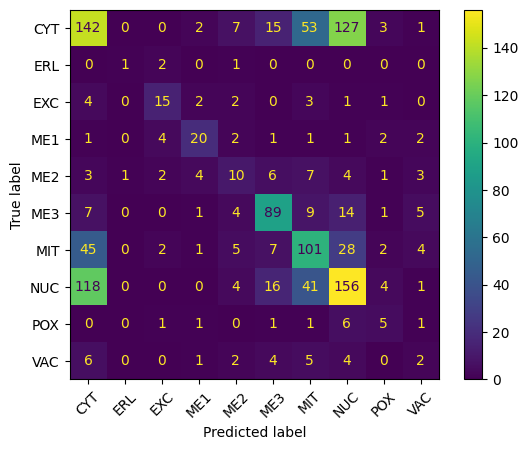

In [245]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_train, y_pred, xticks_rotation=45)
plt.show()

In [246]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "max_depth": [3, 4, 5, 6, 8, 10, None],
    "min_samples_leaf": [1, 2, 5, 10, 20],
    "class_weight": [None, "balanced"],
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid, cv=skf, scoring="f1_macro", n_jobs=-1
)
grid.fit(x_train, y_train)
print(grid.best_params_)
print("Best CV macro F1:", grid.best_score_)

{'class_weight': 'balanced', 'max_depth': 6, 'min_samples_leaf': 1}
Best CV macro F1: 0.495483897434225


In [247]:
best_model = grid.best_estimator_   # already refit on all of x_train

y_test_pred = best_model.predict(x_test)

print(classification_report(y_test, y_test_pred))
print("Macro F1:", f1_score(y_test, y_test_pred, average="macro"))
print("MCC:", matthews_corrcoef(y_test, y_test_pred))

              precision    recall  f1-score   support

         CYT       0.50      0.57      0.53        88
         ERL       0.00      0.00      0.00         1
         EXC       0.67      0.29      0.40         7
         ME1       0.53      1.00      0.69         9
         ME2       0.44      0.40      0.42        10
         ME3       0.74      0.81      0.78        32
         MIT       0.61      0.57      0.59        49
         NUC       0.61      0.51      0.55        85
         POX       0.40      0.50      0.44         4
         VAC       0.00      0.00      0.00         6

    accuracy                           0.56       291
   macro avg       0.45      0.46      0.44       291
weighted avg       0.57      0.56      0.56       291

Macro F1: 0.44073370943046336
MCC: 0.4430186721149816


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


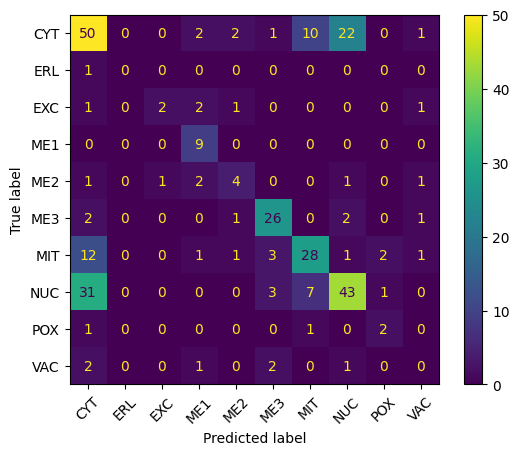

In [248]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test,y_test_pred,xticks_rotation=45)
plt.show()

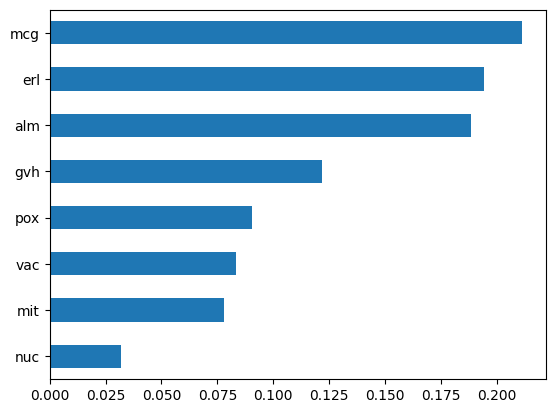

In [249]:
pd.Series(best_model.feature_importances_, index=clean.columns[:-1]).sort_values().plot(kind="barh")
plt.show()

In [250]:
from sklearn.metrics import roc_auc_score
proba = best_model.predict_proba(x_test)
print(roc_auc_score(y_test, proba, multi_class="ovr", average="macro"))

0.7429999020891721


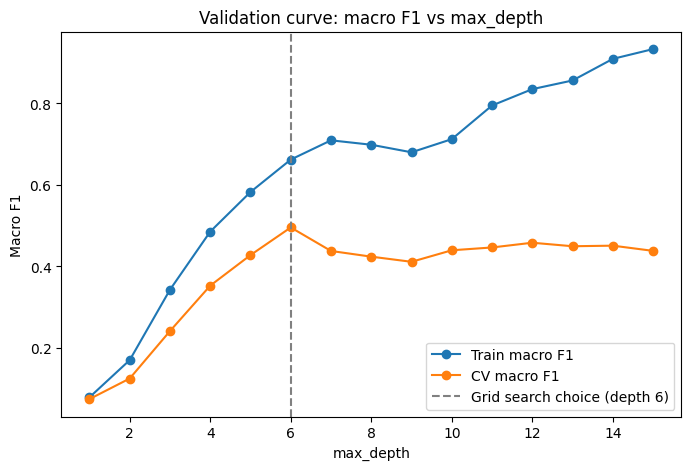

In [251]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import f1_score

depths = range(1, 16)
train_scores = []
cv_scores = []

for d in depths:
    model = DecisionTreeClassifier(max_depth=d, class_weight="balanced", random_state=42)

    # CV macro F1 (average over the 4 folds)
    cv_scores.append(cross_val_score(model, x_train, y_train, cv=skf, scoring="f1_macro").mean())

    # Training macro F1
    model.fit(x_train, y_train)
    train_scores.append(f1_score(y_train, model.predict(x_train), average="macro"))

plt.figure(figsize=(8, 5))
plt.plot(depths, train_scores, marker="o", label="Train macro F1")
plt.plot(depths, cv_scores, marker="o", label="CV macro F1")
plt.axvline(6, color="gray", linestyle="--", label="Grid search choice (depth 6)")
plt.xlabel("max_depth")
plt.ylabel("Macro F1")
plt.title("Validation curve: macro F1 vs max_depth")
plt.legend()
plt.show()

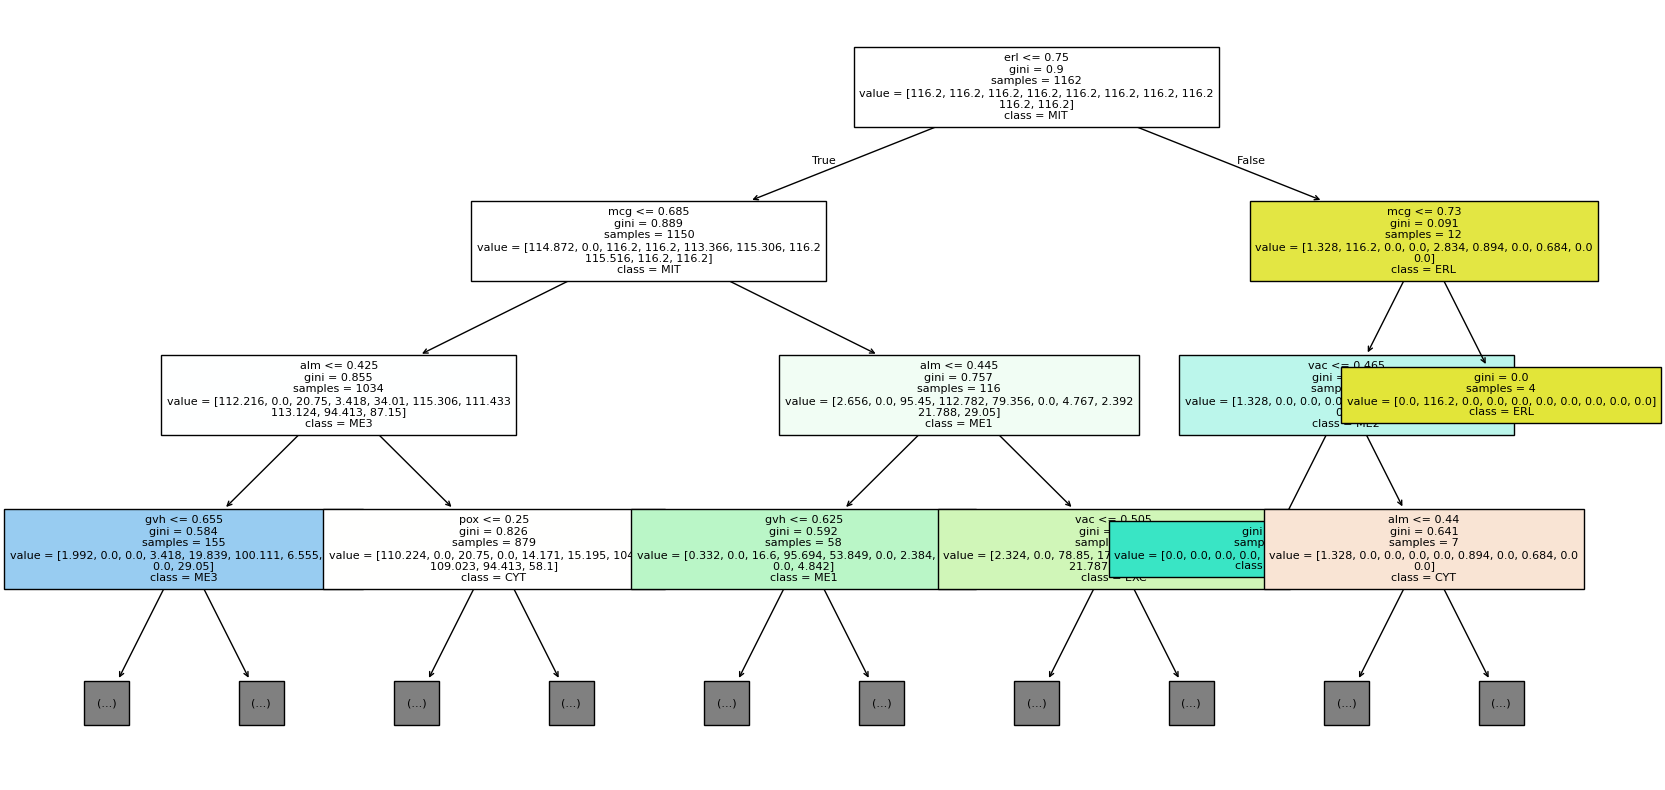

In [252]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(best_model, max_depth=3, feature_names=clean.columns[:-1],
          class_names=best_model.classes_, filled=True, fontsize=8)
plt.show()